# whittaker-trosna: воспроизведение графиков статьи

Ноутбук воспроизводит все графики и результаты вычислительного эксперимента статьи
А. О. Ферубко, О. Д. Казаков о сглаживании Уиттекера с учётом давности наблюдений
(библиотека [whittaker-trosna](https://github.com/89605502155/whittaker-trosna), пакет на PyPI).

| В статье | Раздел ноутбука |
|---|---|
| Рис. 1. Весовые функции | [1](#1.-Весовые-функции-(рис.-1)) |
| Табл. 2. Ошибки сглаживания модельных рядов | [3](#3.-Ошибки-сглаживания-модельных-рядов-(табл.-2)) |
| Рис. 5. Ряд «синусоида и парабола» | [4](#4.-Ряд-«синусоида-и-парабола»-(рис.-5)) |
| Рис. 6. Последние 100 наблюдений модельных рядов | [5](#5.-Модельные-ряды-(рис.-6)) |
| Совпадение реализаций и время работы (табл. 1) | [6](#6.-Совпадение-реализаций-и-время-работы-(табл.-1)) |

Рис. 2–4 в статье являются блок-схемами алгоритмов, а не графиками данных, поэтому здесь не строятся.

Сравниваются три библиотеки с PyPI, каждая «из коробки» (порядок разности $d = 2$, $\lambda$ подбирается
встроенным в пакет способом): **whittaker-trosna 0.2.1**, **whittaker-eilers 0.2.0** и **vam.whittaker 2.0.6**.
Установка окружения описана в `README.md`. Все случайные ряды порождаются с фиксированными зёрнами,
поэтому результаты совпадают со статьёй.

In [1]:
# Если библиотеки ещё не установлены, раскомментируйте (vam.whittaker собирается из исходников, нужен компилятор C):
# %pip install whittaker-trosna==0.2.1 whittaker-eilers==0.2.0 matplotlib pandas
# %pip install --no-binary vam.whittaker vam.whittaker==2.0.6

## 0. Подготовка

In [2]:
import array
import time
import warnings
from dataclasses import dataclass
from importlib.metadata import version

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import vam.whittaker as vw
import whittaker_trosna as wt
from matplotlib import font_manager
from whittaker_eilers import WhittakerSmoother

warnings.filterwarnings("ignore")
%matplotlib inline

for pkg in ("whittaker-trosna", "whittaker-eilers", "vam.whittaker", "numpy", "scipy", "matplotlib"):
    print(f"{pkg:18s} {version(pkg)}")

whittaker-trosna   0.2.1
whittaker-eilers   0.2.0
vam.whittaker      2.0.6
numpy              2.4.6
scipy              1.17.1
matplotlib         3.11.2


Оформление графиков как в статье: шрифт Times New Roman (если он установлен, иначе DejaVu Serif),
десятичная запятая на осях. Цвет и тип линии различаются, поэтому кривые различимы и при чёрно-белой печати.

In [3]:
MM = 1 / 25.4  # размеры рисунков заданы в миллиметрах, как в статье
FONT = "Times New Roman" if any(f.name == "Times New Roman" for f in font_manager.fontManager.ttflist) else "DejaVu Serif"
mpl.rcParams.update(
    {
        "figure.dpi": 150,
        "font.family": FONT,
        "font.size": 9,
        "mathtext.fontset": "custom",
        "mathtext.rm": FONT,
        "mathtext.it": f"{FONT}:italic",
        "axes.linewidth": 0.6,
        "axes.edgecolor": "#444444",
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "xtick.color": "#444444",
        "ytick.color": "#444444",
        "axes.grid": True,
        "grid.color": "#dddddd",
        "grid.linewidth": 0.5,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
    }
)

STYLE = {
    "whittaker-trosna": {"color": "#b2182b", "ls": "-", "lw": 1.6, "label": "whittaker-trosna", "zorder": 5},
    "whittaker-eilers": {"color": "#2166ac", "ls": "--", "lw": 1.4, "label": "whittaker-eilers", "zorder": 4},
    "vam.whittaker": {"color": "#e08214", "ls": "-.", "lw": 1.4, "label": "vam.whittaker", "zorder": 3},
}
DATA_STYLE = {"ls": "none", "marker": "o", "ms": 2.0, "color": "#9a9a9a", "label": "наблюдения", "zorder": 1}
TRUTH_STYLE = {"color": "black", "ls": ":", "lw": 1.2, "label": "истинный сигнал", "zorder": 2}
FRESH = {"color": "#f2e6e6", "zorder": 0, "lw": 0}  # фон участка после изменения


def comma(ax):
    # Десятичная запятая и знак минуса на осях.
    fmt = mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",").replace("-", "−"))
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)

## 1. Весовые функции (рис. 1)

Коэффициент подвижности $c$ зависит от нормированной давности наблюдения $a \in [0, 1]$:
$a = 0$ у последнего наблюдения (оно защищено от сглаживания, $c = 0$), $a = 1$ у наблюдений старше
горизонта $H$ (сглаживаются с полной силой, $c = 1$). Функции берутся прямо из `whittaker_trosna.weights`.

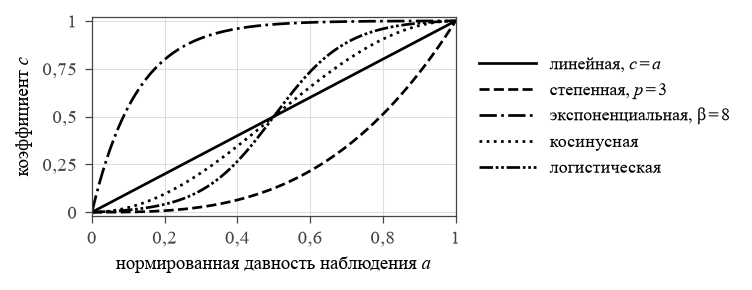

In [4]:
fig, ax = plt.subplots(figsize=(125 * MM, 46 * MM))
a = np.linspace(0, 1, 401)
curves = [
    ("линейная, $c=a$", wt.weights.linear(a), "-"),
    ("степенная, $p=3$", wt.weights.power(a, 3.0), "--"),
    ("экспоненциальная, $\\mathrm{\\beta}=8$", wt.weights.exponential(a, 8.0), "-."),
    ("косинусная", wt.weights.cosine(a), ":"),
    ("логистическая", wt.weights.logistic(a), (0, (5, 1, 1, 1, 1, 1))),
]
for label, c, ls in curves:
    ax.plot(a, c, ls=ls, lw=1.3, color="black", label=label)
ax.set_xlabel("нормированная давность наблюдения $a$")
ax.set_ylabel("коэффициент $c$")
ax.set_xlim(0, 1)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), handlelength=3.2)
comma(ax)
fig.tight_layout(pad=0.3)
plt.show()

## 2. Сравниваемые реализации и модельные ряды

Единый интерфейс к трём библиотекам. whittaker-trosna использует линейную весовую функцию и выбирает $\lambda$
перекрёстной проверкой с исключением по одной точке (`"cv"`), а при коррелированном шуме блочной
перекрёстной проверкой (`"bcv"`). whittaker-eilers выбирает $\lambda$ перекрёстной проверкой, при
коррелированном шуме с прореживанием ряда. vam.whittaker выбирает $\lambda$ по V-кривой.

In [5]:
VAM_LOG_GRID = array.array("d", np.arange(-2.0, 6.01, 0.1))  # сетка log10 λ для V-кривой vam.whittaker


def trosna(y, *, correlated=False):
    return wt.recency_whittaker(y, "bcv" if correlated else "cv")


def eilers(y, *, correlated=False):
    ws = WhittakerSmoother(lmbda=1.0, order=2, data_length=len(y))
    res = ws.smooth_optimal(list(map(float, y)), break_serial_correlation=correlated).get_optimal()
    return np.asarray(res.get_smoothed())


def vam(y, *, correlated=False):
    z, _ = vw.ws2doptv(np.asarray(y, dtype="double"), np.ones(len(y)), VAM_LOG_GRID)
    return np.asarray(z)


IMPLEMENTATIONS = {"whittaker-trosna": trosna, "whittaker-eilers": eilers, "vam.whittaker": vam}


def smooth_all(y, correlated=False):
    return {name: fn(y, correlated=correlated) for name, fn in IMPLEMENTATIONS.items()}


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

Пять модельных рядов из $n = 400$ наблюдений с шагом 1 с. Последние `tail` наблюдений каждого ряда
образуют участок после изменения поведения (у контрольного ряда изменения нет, ошибка «после изменения»
считается по последним 20 наблюдениям). Шум белый или AR(1) с той же дисперсией.

In [6]:
N = 400


def sine_parabola(n, tail, cycles=3, rise=8.0):
    # Три периода синусоиды, затем парабола с гладкой (C¹) стыковкой.
    m = n - tail
    x = np.arange(n, dtype=float)
    s = np.sin(2 * np.pi * cycles * x / m)
    u = (x[m:] - m) / tail
    s[m:] = 2 * np.pi * cycles / m * (x[m:] - m) + rise * u**2
    return s


def step(n, tail, height=2.5):
    # Медленный дрейф и скачок уровня.
    x = np.arange(n, dtype=float)
    s = 0.5 * np.sin(2 * np.pi * x / 250) + 0.002 * x
    s[n - tail :] += height
    return s


def trend_break(n, tail, slope=0.12):
    # Излом тренда: после колебаний начинается линейный рост.
    x = np.arange(n, dtype=float)
    s = 0.4 * np.sin(2 * np.pi * x / 120)
    m = n - tail
    s[m:] += slope * (x[m:] - m)
    return s


def memory(n, tail):
    # Потребление памяти ВМ: пила сборки мусора, затем ускоряющийся рост.
    x = np.arange(n, dtype=float)
    s = (x % 80) / 80 + 0.3 * np.sin(2 * np.pi * x / 200)
    m = n - tail
    u = (x[m:] - m) / tail
    s[m:] += 4.0 * u**1.5
    return s


def stationary(n, tail):
    # Контроль: синусоида без смены режима.
    x = np.arange(n, dtype=float)
    return np.sin(2 * np.pi * 3 * x / n)


SIGNALS = {
    "sine_parabola": sine_parabola,
    "step": step,
    "trend_break": trend_break,
    "memory": memory,
    "stationary": stationary,
}


@dataclass(frozen=True)
class Scenario:
    key: str
    title: str
    sigma: float  # СКО шума
    tail: int  # длительность участка после изменения
    phi: float = 0.0  # коэффициент AR(1) шума; 0 — белый шум

    @property
    def correlated(self):
        return self.phi > 0

    def sample(self, seed):
        s = SIGNALS[self.key](N, self.tail)
        rng = np.random.default_rng(seed)
        e = rng.normal(0.0, 1.0, N)
        if self.phi > 0:
            for i in range(1, N):
                e[i] = self.phi * e[i - 1] + np.sqrt(1 - self.phi**2) * e[i]
        return s, s + self.sigma * e


SCENARIOS = {
    sc.key: sc
    for sc in [
        Scenario("sine_parabola", "Синусоида → парабола", sigma=0.6, tail=20),
        Scenario("step", "Скачок уровня", sigma=0.5, tail=15),
        Scenario("trend_break", "Излом тренда", sigma=0.5, tail=15),
        Scenario("memory", "Потребление памяти, шум AR(1)", sigma=0.4, tail=25, phi=0.6),
        Scenario("stationary", "Без изменения поведения ряда", sigma=0.6, tail=20),
    ]
}

## 3. Ошибки сглаживания модельных рядов (табл. 2)

Для каждого ряда моделируется `RUNS` реализаций шума (зёрна 0, 1, …). Вычисляются СКО относительно
истинного сигнала на участке после изменения и на остальной части ряда, а также среднее смещение оценки
последнего наблюдения. В статье `RUNS = 100`, расчёт занимает несколько минут; для быстрой проверки
можно уменьшить.

In [7]:
RUNS = 100


def scenario_stats(sc, runs):
    out = {k: {"tail": [], "body": [], "end": []} for k in IMPLEMENTATIONS}
    for seed in range(runs):
        s, y = sc.sample(seed)
        for name, z in smooth_all(y, sc.correlated).items():
            out[name]["tail"].append(rmse(z[-sc.tail :], s[-sc.tail :]))
            out[name]["body"].append(rmse(z[: -sc.tail], s[: -sc.tail]))
            out[name]["end"].append(float(z[-1] - s[-1]))
    return {
        name: {
            "СКО после изменения": np.mean(v["tail"]),
            "СКО на остальной части": np.mean(v["body"]),
            "Смещение последнего значения": np.mean(v["end"]),
            "СКО последнего значения": np.sqrt(np.mean(np.square(v["end"]))),
            "_std_tail": np.std(v["tail"]),
        }
        for name, v in out.items()
    }


t0 = time.perf_counter()
stats = {key: scenario_stats(sc, RUNS) for key, sc in SCENARIOS.items()}
print(f"расчёт: {time.perf_counter() - t0:.0f} с")

table2 = pd.DataFrame(
    {
        (metric, lib): [stats[key][lib][metric] for key in SCENARIOS]
        for metric in ("СКО после изменения", "СКО на остальной части", "Смещение последнего значения")
        for lib in IMPLEMENTATIONS
    },
    index=[sc.title for sc in SCENARIOS.values()],
)
se_max = max(r[k]["_std_tail"] for r in stats.values() for k in IMPLEMENTATIONS) / RUNS**0.5
print(f"стандартная ошибка средних не превышает {se_max:.2f}")
table2.style.format("{:.2f}")

расчёт: 92 с
стандартная ошибка средних не превышает 0.03


СКО оценки последнего значения (обсуждается в тексте статьи после рис. 5): у whittaker-trosna последнее
наблюдение защищено от сглаживания, поэтому эта ошибка близка к СКО шума.

In [8]:
pd.DataFrame(
    {lib: [stats[key][lib]["СКО последнего значения"] for key in SCENARIOS] for lib in IMPLEMENTATIONS},
    index=[sc.title for sc in SCENARIOS.values()],
).style.format("{:.2f}")

,whittaker-trosna,whittaker-eilers,vam.whittaker
Синусоида → парабола,0.58,0.71,2.75
Скачок уровня,0.48,0.37,0.34
Излом тренда,0.48,0.37,0.52
"Потребление памяти, шум AR(1)",0.37,0.36,0.87
Без изменения поведения ряда,0.58,0.22,0.23


## 4. Ряд «синусоида и парабола» (рис. 5)

Для рисунка выбирается типичная реализация: зерно с медианным выигрышем whittaker-trosna над
whittaker-eilers по СКО на участке после изменения (среди первых 40 зёрен).

In [9]:
def median_seed(sc, runs=40):
    gains = []
    for seed in range(runs):
        s, y = sc.sample(seed)
        z = smooth_all(y, sc.correlated)
        err = {k: rmse(v[-sc.tail :], s[-sc.tail :]) for k, v in z.items()}
        gains.append(err["whittaker-eilers"] - err["whittaker-trosna"])
    return int(np.argsort(gains)[len(gains) // 2])


def draw(ax, x, s, y, zs, sl=slice(None)):
    ax.plot(x[sl], y[sl], **DATA_STYLE)
    ax.plot(x[sl], s[sl], **TRUTH_STYLE)
    for name, z in zs.items():
        ax.plot(x[sl], z[sl], **STYLE[name])

Панель «в» показывает зависимость СКО после изменения от длительности этого участка $L$. Кривизна параболы
при любом $L$ одинакова, для каждого $L$ моделируется `TL_RUNS` реализаций шума (зёрна 1000, 1001, …;
в статье 25).

In [10]:
TL_RUNS = 25
LENGTHS = [5, 10, 15, 20, 30, 40, 60, 80, 100]

tail_rmse = {k: [] for k in IMPLEMENTATIONS}
for L in LENGTHS:
    s = sine_parabola(N, L, rise=8.0 * L / 20)
    acc = {k: [] for k in IMPLEMENTATIONS}
    for seed in range(TL_RUNS):
        y = s + 0.6 * np.random.default_rng(1000 + seed).normal(size=N)
        for name, fn in IMPLEMENTATIONS.items():
            acc[name].append(rmse(fn(y)[-L:], s[-L:]))
    for name in IMPLEMENTATIONS:
        tail_rmse[name].append(float(np.mean(acc[name])))

pd.DataFrame(tail_rmse, index=pd.Index(LENGTHS, name="L, с")).T.style.format("{:.2f}")

"L, с",5,10,15,20,30,40,60,80,100
whittaker-trosna,0.53,0.40,0.32,0.28,0.23,0.21,0.18,0.17,0.16
whittaker-eilers,0.53,0.56,0.38,0.29,0.24,0.19,0.17,0.15,0.13
vam.whittaker,0.58,0.96,1.19,1.05,0.32,0.26,0.21,0.18,0.15


зерно реализации: 39


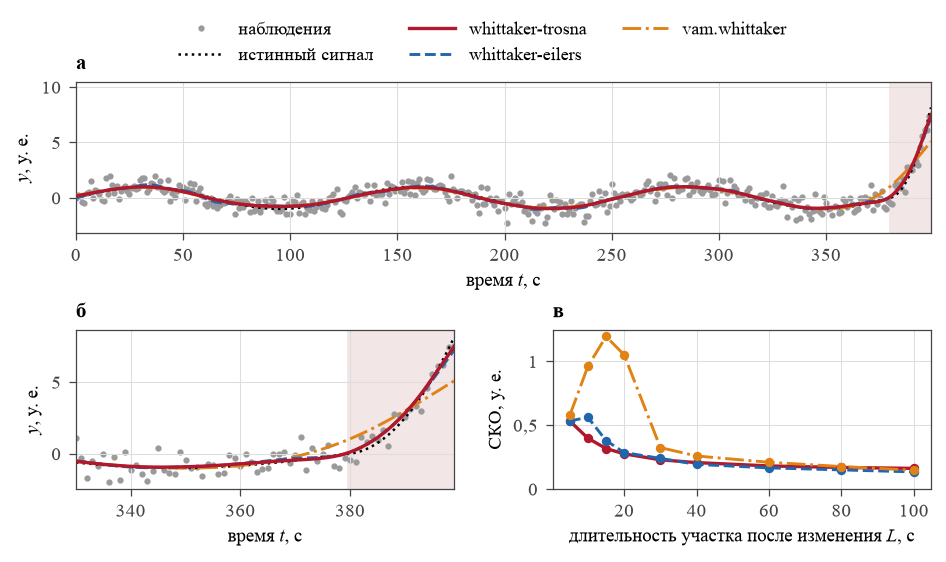

In [11]:
sc = SCENARIOS["sine_parabola"]
seed = median_seed(sc)
print("зерно реализации:", seed)
s, y = sc.sample(seed)
zs = smooth_all(y)
x = np.arange(N)

fig = plt.figure(figsize=(160 * MM, 92 * MM))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.05], hspace=0.62, wspace=0.26)

ax_a = fig.add_subplot(gs[0, :])
draw(ax_a, x, s, y, zs)
ax_a.axvspan(N - sc.tail - 0.5, N - 0.5, **FRESH)
ax_a.set_xlim(0, N - 1)
ax_a.set_ylim(-3.2, 10.5)
ax_a.set_xlabel("время $t$, с")
ax_a.set_ylabel("$y$, у. е.")
ax_a.set_title("а", loc="left", fontsize=10, fontweight="bold")
comma(ax_a)

ax_b = fig.add_subplot(gs[1, 0])
draw(ax_b, x, s, y, zs, slice(N - 70, N))
ax_b.axvspan(N - sc.tail - 0.5, N - 0.5, **FRESH)
ax_b.set_xlim(N - 70, N - 1)
ax_b.set_xlabel("время $t$, с")
ax_b.set_ylabel("$y$, у. е.")
ax_b.set_title("б", loc="left", fontsize=10, fontweight="bold")
comma(ax_b)

ax_c = fig.add_subplot(gs[1, 1])
for name, st in STYLE.items():
    ax_c.plot(LENGTHS, tail_rmse[name], ls=st["ls"], color=st["color"], lw=st["lw"], marker="o", ms=3.5)
ax_c.set_xlabel("длительность участка после изменения $L$, с")
ax_c.set_ylabel("СКО, у. е.")
ax_c.set_title("в", loc="left", fontsize=10, fontweight="bold")
ax_c.set_ylim(0, None)
comma(ax_c)

handles, labels = ax_a.get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0), handlelength=2.6)
fig.subplots_adjust(left=0.07, right=0.975, top=0.86, bottom=0.11)
plt.show()

## 5. Модельные ряды (рис. 6)

Последние 100 наблюдений четырёх рядов: а – скачок уровня; б – излом тренда; в – потребление памяти с шумом
AR(1); г – ряд без изменения поведения. Для каждого ряда показана реализация с медианным выигрышем.

а) Скачок уровня: зерно 33


б) Излом тренда: зерно 11


в) Потребление памяти, шум AR(1): зерно 8


г) Без изменения поведения ряда: зерно 22


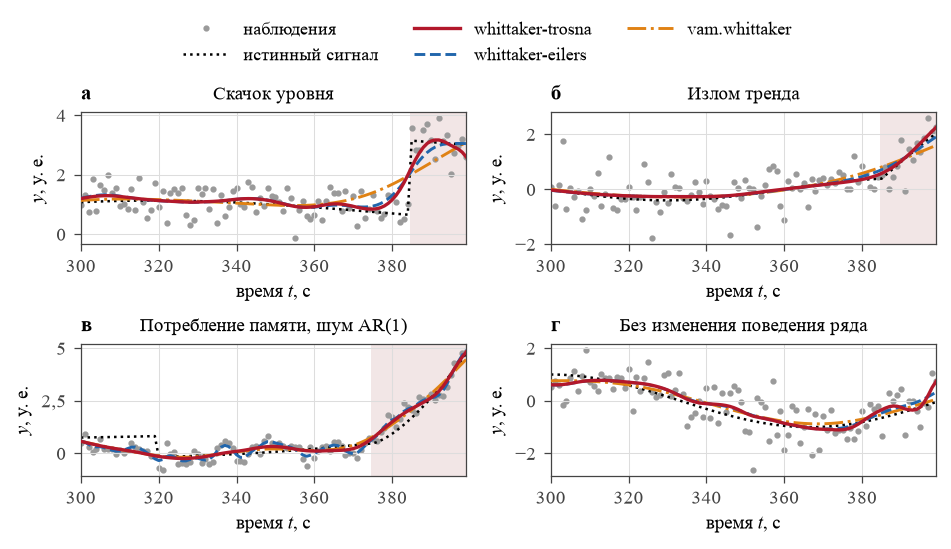

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(160 * MM, 90 * MM))
x = np.arange(N)
for ax, key, letter in zip(axes.ravel(), ["step", "trend_break", "memory", "stationary"], "абвг"):
    sc = SCENARIOS[key]
    seed = median_seed(sc)
    print(f"{letter}) {sc.title}: зерно {seed}")
    s, y = sc.sample(seed)
    zs = smooth_all(y, correlated=sc.correlated)
    draw(ax, x, s, y, zs, slice(N - 100, N))
    if key != "stationary":
        ax.axvspan(N - sc.tail - 0.5, N - 0.5, **FRESH)
    ax.set_xlim(N - 100, N - 1)
    ax.set_title(letter, loc="left", fontsize=10, fontweight="bold")
    ax.set_title(sc.title, loc="center", fontsize=9)
    ax.set_xlabel("время $t$, с")
    ax.set_ylabel("$y$, у. е.")
    comma(ax)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0), handlelength=2.6)
fig.subplots_adjust(left=0.07, right=0.975, top=0.80, bottom=0.115, hspace=0.75, wspace=0.22)
plt.show()

## 6. Совпадение реализаций и время работы (табл. 1)

При $c \equiv 1$ метод сводится к классическому сглаживанию Уиттекера, поэтому при одинаковой $\lambda$ три
библиотеки должны давать одинаковый результат. Проверка на случайных блужданиях длиной до $10^4$.

In [13]:
def classic_fixed(name, y, lam):
    # Классическое сглаживание при заданной λ.
    if name == "whittaker-trosna":
        return wt.whittaker(y, lam)
    if name == "whittaker-eilers":
        return np.asarray(WhittakerSmoother(lmbda=lam, order=2, data_length=len(y)).smooth(list(map(float, y))))
    return np.asarray(vw.ws2d(np.asarray(y, dtype="double"), lam, np.ones(len(y))))


rng = np.random.default_rng(7)
worst = 0.0
for n in (100, 1000, 10000):
    y = np.cumsum(rng.normal(size=n))
    for lam in (1.0, 1e2, 1e4):
        ref = classic_fixed("whittaker-trosna", y, lam)
        for other in ("whittaker-eilers", "vam.whittaker"):
            worst = max(worst, float(np.max(np.abs(classic_fixed(other, y, lam) - ref))))
print(f"наибольшее расхождение реализаций: {worst:.1e}")

наибольшее расхождение реализаций: 3.0e-10


Время сглаживания при заданной $\lambda = 100$ и с автоматическим выбором $\lambda$ (медиана повторов, мс).
Абсолютные значения зависят от компьютера, соотношение между библиотеками сохраняется. Выбор $\lambda$
в whittaker-trosna 0.2.1 при $n$ больше примерно 4000 завершается ошибкой, поэтому измеряется только
для $n \le 3000$.

In [14]:
def median_ms(fn, repeats):
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t0)
    return 1e3 * float(np.median(ts))


rng = np.random.default_rng(3)
rows = {}
for n in (1000, 3000, 10000, 100000):
    y = np.sin(np.arange(n) / 50) + rng.normal(0.0, 0.3, n)
    row = {}
    for name in IMPLEMENTATIONS:
        row[(name, "λ = 100")] = median_ms(lambda: classic_fixed(name, y, 100.0), 5)
        if n <= 3000:
            row[(name, "выбор λ")] = median_ms(lambda: IMPLEMENTATIONS[name](y), 3)
    rows[n] = row
timing = pd.DataFrame(rows).T
timing.index.name = "n"
timing.style.format("{:.1f}", na_rep="–")